In [9]:
import numpy as np
import pandas as pd

# Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")

In [10]:
df

,Week,Team ID,Team Name,Score,Status
0,1,15,Chris Hart Attack,166.96,Played
1,1,3,Very Polite Boys,161.66,Played
2,1,10,Daddy Fat Sacks,126.62,Bye
3,1,13,Noah's Gold,146.10,Played
4,1,7,East Palestine's Most Wanted,116.36,Played
...,...,...,...,...,...
86,7,7,East Palestine's Most Wanted,98.54,Played
87,7,6,Sixty-Niners,111.24,Played
88,7,9,Sean's Hart,127.60,Played
89,7,2,Wet Dawgs,91.68,Played


In [11]:
# Clean out any rows with missing team names or scores
df = df.dropna(subset=["Team Name", "Score"]).copy()


In [12]:
df

,Week,Team ID,Team Name,Score,Status
0,1,15,Chris Hart Attack,166.96,Played
1,1,3,Very Polite Boys,161.66,Played
2,1,10,Daddy Fat Sacks,126.62,Bye
3,1,13,Noah's Gold,146.10,Played
4,1,7,East Palestine's Most Wanted,116.36,Played
...,...,...,...,...,...
86,7,7,East Palestine's Most Wanted,98.54,Played
87,7,6,Sixty-Niners,111.24,Played
88,7,9,Sean's Hart,127.60,Played
89,7,2,Wet Dawgs,91.68,Played


In [13]:
# Clean out any rows with missing team names or scores
df = df.dropna(subset=["Team Name", "Score"]).copy()

# Filter out bye weeks so they don't mess up weekly scoring pools
df_played = df[df["Status"] == "Played"].copy()

# Get a unique list of actual active team names
unique_teams = df_played["Team Name"].unique()

# Initialize dictionary with explicit keys for Wins, Losses, Ties
all_play_records = {
    team: {"Wins": 0, "Losses": 0, "Ties": 0} for team in unique_teams
}

In [14]:
for week, group in df_played.groupby("Week"):
  scores = group[["Team Name", "Score"]].values.tolist()

  for i in range(len(scores)):
    team_a, score_a = scores[i]
    for j in range(len(scores)):
      if i == j:
        continue
      team_b, score_b = scores[j]

      if score_a > score_b:
        all_play_records[team_a]["Wins"] += 1
      elif score_a < score_b:
        all_play_records[team_a]["Losses"] += 1
      else:
        all_play_records[team_a]["Ties"] += 1

# Convert dictionary to DataFrame safely using 'index' orientation
all_play_df_record_bye = pd.DataFrame.from_dict(all_play_records, orient="index")

In [47]:
bye_included = df.dropna(subset=["Team Name","Score"]).copy()
all_play_records_bye = {
    team: {"Wins": 0, "Losses": 0, "Ties": 0} for team in unique_teams
}

In [48]:
for week, group in bye_included.groupby("Week"):
  scores = group[["Team Name", "Score"]].values.tolist()

  for i in range(len(scores)):
    team_a, score_a = scores[i]
    for j in range(len(scores)):
      if i == j:
        continue
      team_b, score_b = scores[j]

      if score_a > score_b:
        all_play_records_bye[team_a]["Wins"] += 1
      elif score_a < score_b:
        all_play_records_bye[team_a]["Losses"] += 1
      else:
        all_play_records_bye[team_a]["Ties"] += 1

# Convert dictionary to DataFrame safely using 'index' orientation
all_play_df_bye = pd.DataFrame.from_dict(all_play_records_bye, orient="index")

In [43]:
all_play_df

,Wins,Losses,Ties
Chris Hart Attack,43,23,0
Very Polite Boys,49,28,0
Noah's Gold,32,34,0
East Palestine's Most Wanted,32,45,0
My Lung Hurts,19,47,0
Sean's Hart,48,18,0
CeeDeez Nuts,61,16,0
I’ll OKLA-OWN-YA,35,42,0
Aaron Rodgers Newest Victim,23,43,0
Sixty-Niners,11,55,0


In [49]:
all_play_df_bye

,Wins,Losses,Ties
Chris Hart Attack,54,30,0
Very Polite Boys,55,29,0
Noah's Gold,45,39,0
East Palestine's Most Wanted,36,48,0
My Lung Hurts,21,63,0
Sean's Hart,65,19,0
CeeDeez Nuts,67,17,0
I’ll OKLA-OWN-YA,40,44,0
Aaron Rodgers Newest Victim,27,57,0
Sixty-Niners,13,71,0


In [16]:

# Reset index so 'Team Name' becomes a proper column
all_play_df.index.name = "Team Name"
all_play_df = all_play_df.reset_index()

# Calculate total games and All-Play Win Percentage
all_play_df["Total_Games"] = (
    all_play_df["Wins"] + all_play_df["Losses"] + all_play_df["Ties"]
)
all_play_df["All_Play_Win_%"] = (
    all_play_df["Wins"] + (0.5 * all_play_df["Ties"])
) / all_play_df["Total_Games"]

In [17]:
all_play_df

,Team Name,Wins,Losses,Ties,Total_Games,All_Play_Win_%
0,Chris Hart Attack,43,23,0,66,0.651515
1,Very Polite Boys,49,28,0,77,0.636364
2,Noah's Gold,32,34,0,66,0.484848
3,East Palestine's Most Wanted,32,45,0,77,0.415584
4,My Lung Hurts,19,47,0,66,0.287879
5,Sean's Hart,48,18,0,66,0.727273
6,CeeDeez Nuts,61,16,0,77,0.792208
7,I’ll OKLA-OWN-YA,35,42,0,77,0.454545
8,Aaron Rodgers Newest Victim,23,43,0,66,0.348485
9,Sixty-Niners,11,55,0,66,0.166667


In [18]:
# Sort by the best All-Play record
all_play_df = all_play_df.sort_values(
    by="All_Play_Win_%", ascending=False
).reset_index(drop=True)

In [19]:
all_play_df

,Team Name,Wins,Losses,Ties,Total_Games,All_Play_Win_%
0,CeeDeez Nuts,61,16,0,77,0.792208
1,Sean's Hart,48,18,0,66,0.727273
2,Chris Hart Attack,43,23,0,66,0.651515
3,Very Polite Boys,49,28,0,77,0.636364
4,Wet Dawgs,45,32,0,77,0.584416
5,Drake Maye,40,37,0,77,0.519481
6,Noah's Gold,32,34,0,66,0.484848
7,I’ll OKLA-OWN-YA,35,42,0,77,0.454545
8,East Palestine's Most Wanted,32,45,0,77,0.415584
9,Daddy Fat Sacks,24,42,0,66,0.363636


In [20]:
matchup_logs = []

# Group by each week and evaluate head-to-head against everyone else that week
for week, group in df_played.groupby("Week"):
  scores = group[["Team Name", "Score"]].values.tolist()

  # Compare every team's score against every other team's score that week
  for i in range(len(scores)):
    team_a, score_a = scores[i]
    for j in range(len(scores)):
      if i == j:
        continue
      team_b, score_b = scores[j]

      # Determine the result from Team A's perspective
      if score_a > score_b:
        result = "Win"
      elif score_a < score_b:
        result = "Loss"
      else:
        result = "Tie"

      matchup_logs.append({
          "Week": week,
          "Team": team_a,
          "Team_Score": score_a,
          "Opponent": team_b,
          "Opponent_Score": score_b,
          "Result": result,
      })

# Convert the detailed logs into a DataFrame
df_detailed = pd.DataFrame(matchup_logs)

# Print a quick preview of the first few rows in your terminal
print(df_detailed.head(10).to_string(index=False))

# Save it to a new CSV file for Excel
df_detailed.to_csv("all_play_detailed_matrix.csv", index=False)
print(
    "\nSaved detailed weekly matrix successfully to"
    " all_play_detailed_matrix.csv!"
)

 Week              Team  Team_Score                     Opponent  Opponent_Score Result
    1 Chris Hart Attack      166.96             Very Polite Boys          161.66    Win
    1 Chris Hart Attack      166.96                  Noah's Gold          146.10    Win
    1 Chris Hart Attack      166.96 East Palestine's Most Wanted          116.36    Win
    1 Chris Hart Attack      166.96                My Lung Hurts          122.68    Win
    1 Chris Hart Attack      166.96                  Sean's Hart          159.70    Win
    1 Chris Hart Attack      166.96                 CeeDeez Nuts          146.80    Win
    1 Chris Hart Attack      166.96             I’ll OKLA-OWN-YA          139.08    Win
    1 Chris Hart Attack      166.96  Aaron Rodgers Newest Victim           85.94    Win
    1 Chris Hart Attack      166.96                 Sixty-Niners           93.06    Win
    1 Chris Hart Attack      166.96                   Drake Maye          140.32    Win

Saved detailed weekly matrix su

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [ ]:
# 1. Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")
df = df.dropna(subset=["Team Name", "Score"]).copy()
df_played = df[df["Status"] == "Played"].copy()

teams = sorted(df_played["Team Name"].unique())

# 2. Build the head-to-head win matrix numerically (Row team wins against Column team)
matrix_data = {team: {opp: 0 for opp in teams} for team in teams}

for week, group in df_played.groupby("Week"):
  scores = group.set_index("Team Name")["Score"].to_dict()

  for t1 in teams:
    if t1 not in scores:
      continue
    for t2 in teams:
      if t1 == t2 or t2 not in scores:
        continue

      if scores[t1] > scores[t2]:
        matrix_data[t1][t2] += 1

# Convert to DataFrame and make a writable copy of the underlying array

In [26]:
df_matrix = pd.DataFrame(matrix_data).T

In [27]:
df_matrix

,Aaron Rodgers Newest Victim,CeeDeez Nuts,Chris Hart Attack,Daddy Fat Sacks,Drake Maye,East Palestine's Most Wanted,I’ll OKLA-OWN-YA,My Lung Hurts,Noah's Gold,Sean's Hart,Sixty-Niners,Very Polite Boys,Wet Dawgs
Aaron Rodgers Newest Victim,0,1,1,2,1,4,3,2,3,0,2,2,2
CeeDeez Nuts,5,0,3,5,5,6,7,6,5,4,6,5,4
Chris Hart Attack,4,3,0,4,4,4,3,4,3,2,5,4,3
Daddy Fat Sacks,3,1,1,0,3,2,2,1,2,1,3,2,3
Drake Maye,5,2,2,3,0,5,4,4,3,1,6,2,3
East Palestine's Most Wanted,2,1,2,4,2,0,4,4,3,2,4,2,2
I’ll OKLA-OWN-YA,3,0,3,4,3,3,0,5,3,1,5,2,3
My Lung Hurts,3,0,1,4,2,2,1,0,0,0,4,0,2
Noah's Gold,2,1,2,3,3,3,3,5,0,2,4,2,2
Sean's Hart,5,2,3,4,5,4,5,5,3,0,5,3,4


In [25]:


# Fill diagonal with NaNs safely
matrix_vals = df_matrix.values.copy()
np.fill_diagonal(matrix_vals, np.nan)
df_matrix_plot = pd.DataFrame(matrix_vals, index=df_matrix.index, columns=df_matrix.columns)

# 3. Plot a gorgeous Seaborn Heatmap in Jupyter
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_matrix_plot,
    annot=True,
    cmap="RdYlGn",
    fmt="g",
    linewidths=0.5,
    cbar=False,
    na_color="gray",
)

plt.title("All-Play Head-to-Head Win Matrix", fontsize=14, pad=15)
plt.xlabel("Opponent", fontsize=11)
plt.ylabel("Team", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

ValueError: cannot convert float NaN to integer

ValueError: cannot convert float NaN to integer

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")
df = df.dropna(subset=["Team Name", "Score"]).copy()
df_played = df[df["Status"] == "Played"].copy()

teams = sorted(df_played["Team Name"].unique())

# 2. Loop through each week to generate a week-by-week breakdown
# (Or you can pick a specific week, e.g., week = 1)
for week_num, group in df_played.groupby("Week"):
  scores = group.set_index("Team Name")["Score"].to_dict()

  # Initialize a zero matrix for this specific week
  weekly_matrix = {team: {opp: 0 for opp in teams} for team in teams}

  for t1 in teams:
    if t1 not in scores:
      continue
    for t2 in teams:
      if t1 == t2 or t2 not in scores:
        continue

      # 1 if t1 beat t2 that week, else 0
      if scores[t1] > scores[t2]:
        weekly_matrix[t1][t2] = 1

  # Convert to DataFrame
  df_week = pd.DataFrame(weekly_matrix).T

In [30]:
print(df_week)

                              Aaron Rodgers Newest Victim  CeeDeez Nuts  \
Aaron Rodgers Newest Victim                             0             0   
CeeDeez Nuts                                            1             0   
Chris Hart Attack                                       1             1   
Daddy Fat Sacks                                         0             0   
Drake Maye                                              1             0   
East Palestine's Most Wanted                            1             0   
I’ll OKLA-OWN-YA                                        1             0   
My Lung Hurts                                           1             0   
Noah's Gold                                             1             0   
Sean's Hart                                             1             1   
Sixty-Niners                                            1             0   
Very Polite Boys                                        1             1   
Wet Dawgs                

In [29]:
  # Make writable copy for NaN filling on the diagonal
  vals = df_week.values.copy()
  np.fill_diagonal(vals, np.nan)
  df_plot = pd.DataFrame(vals, index=df_week.index, columns=df_week.columns)

  # Plot a mini heatmap for this specific week
  plt.figure(figsize=(8, 6))
  sns.heatmap(
      df_plot,
      annot=True,
      cmap="RdYlGn",
      fmt="g",
      linewidths=0.5,
      cbar=False,
      na_color="gray",
  )
  plt.title(
      f"Week {week_num} All-Play Head-to-Head Matrix (1 = Win, 0 = Loss)",
      fontsize=12,
      pad=12,
  )
  plt.xlabel("Opponent", fontsize=10)
  plt.ylabel("Team", fontsize=10)
  plt.xticks(rotation=45, ha="right")
  plt.yticks(rotation=0)
  plt.tight_layout()
  plt.show()

ValueError: cannot convert float NaN to integer

ValueError: cannot convert float NaN to integer

In [32]:
import numpy as np
import pandas as pd

# 1. Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")
df = df.dropna(subset=["Team Name", "Score"]).copy()
df_played = df[df["Status"] == "Played"].copy()

teams = sorted(df_played["Team Name"].unique())

# 2. Loop through each week to generate the custom W/L matrix with totals
for week_num, group in df_played.groupby("Week"):
  # Map each team to their score for this specific week
  scores = group.set_index("Team Name")["Score"].to_dict()

  matrix_data = {}
  for t1 in teams:
    matrix_data[t1] = {}
    score_1 = scores.get(t1, np.nan)

    for t2 in teams:
      if t1 == t2 or pd.isna(score_1) or t2 not in scores:
        matrix_data[t1][t2] = "-"
        continue

      score_2 = scores[t2]

      # Assign W, L, or T
      if score_1 > score_2:
        matrix_data[t1][t2] = "W"
      elif score_1 < score_2:
        matrix_data[t1][t2] = "L"
      else:
        matrix_data[t1][t2] = "T"

  # Convert to DataFrame
  df_week = pd.DataFrame(matrix_data).T  # Rows = Team, Cols = Opponent
  df_week = df_week[teams]  # Ensure column order matches row order

  # 3. Calculate Totals on both sides
  # Count total Wins per row team
  df_week["Total Wins"] = (df_week == "W").sum(axis=1)
  df_week["Total Losses"] = (df_week == "L").sum(axis=1)
  df_week["Record"] = (
      df_week["Total Wins"].astype(str)
      + "-"
      + df_week["Total Losses"].astype(str)
  )

  # Clean up view to show the W/L grid plus the Record column
  display_cols = teams + ["Record"]
  final_display = df_week[display_cols]

  print(f"\n==================== WEEK {week_num} ALL-PLAY MATRIX ====================")
  print(final_net_display if "final_net_display" in locals() else final_display.to_string())
  print("=" * 70)


==================== WEEK 1 ALL-PLAY MATRIX ====================
                             Aaron Rodgers Newest Victim CeeDeez Nuts Chris Hart Attack Daddy Fat Sacks Drake Maye East Palestine's Most Wanted I’ll OKLA-OWN-YA My Lung Hurts Noah's Gold Sean's Hart Sixty-Niners Very Polite Boys Wet Dawgs Record
Aaron Rodgers Newest Victim                            -            L                 L               -          L                            L                L             L           L           L            L                L         L   0-11
CeeDeez Nuts                                           W            -                 L               -          W                            W                W             W           W           L            W                L         W    8-3
Chris Hart Attack                                      W            W                 -               -          W                            W                W             W           W          

AttributeError: QuadMesh.set() got an unexpected keyword argument 'na_color'

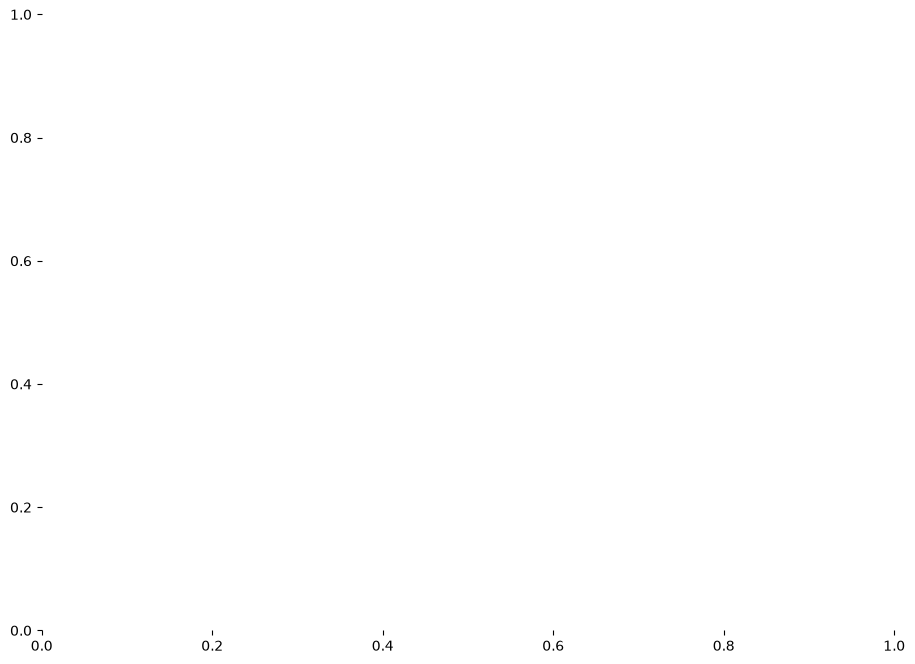

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")
df = df.dropna(subset=["Team Name", "Score"]).copy()
df_played = df[df["Status"] == "Played"].copy()

teams = sorted(df_played["Team Name"].unique())

# 2. Loop through each week and generate a color-coded heatmap matrix
for week_num, group in df_played.groupby("Week"):
  scores = group.set_index("Team Name")["Score"].to_dict()

  matrix_data = {}
  numeric_matrix = {}

  for t1 in teams:
    matrix_data[t1] = {}
    numeric_matrix[t1] = {}
    score_1 = scores.get(t1, np.nan)

    for t2 in teams:
      if t1 == t2 or pd.isna(score_1) or t2 not in scores:
        matrix_data[t1][t2] = ""
        numeric_matrix[t1][t2] = np.nan
        continue

      score_2 = scores[t2]

      # Assign W/L text for annotations and 1/0 for color coding
      if score_1 > score_2:
        matrix_data[t1][t2] = "W"
        numeric_matrix[t1][t2] = 1  # Win = Green
      elif score_1 < score_2:
        matrix_data[t1][t2] = "L"
        numeric_matrix[t1][t2] = 0  # Loss = Red
      else:
        matrix_data[t1][t2] = "T"
        numeric_matrix[t1][t2] = 0.5

  # Convert to DataFrames
  df_text = pd.DataFrame(matrix_data).T[teams]
  df_num = pd.DataFrame(numeric_matrix).T[teams]

  # Calculate total wins for the side label
  total_wins = (df_text == "W").sum(axis=1)
  total_losses = (df_text == "L").sum(axis=1)
  records = [f"{w}-{l}" for w, l in zip(total_wins, total_losses)]
  df_text["Record"] = records

  # Plot the heatmap
  plt.figure(figsize=(11, 8))
  ax = sns.heatmap(
      df_num,
      annot=df_text.drop(columns=["Record"]).values,
      fmt="",
      cmap="RdYlGn",
      vmin=0,
      vmax=1,
      linewidths=0.5,
      cbar=False,
      na_color="#2b2b2b",  # Dark gray for self-matches/byes
  )

  # Customizations
  plt.title(
      f"Week {week_num} All-Play Head-to-Head Matrix", fontsize=14, pad=15
  )
  plt.xlabel("Opponent", fontsize=11)
  plt.ylabel("Team", fontsize=11)
  plt.xticks(rotation=45, ha="right")
  plt.yticks(rotation=0)

  # Attach the weekly total record to the right side of the plot
  ylocs = ax.get_yticks()
  for i, record in enumerate(records):
    ax.text(
        len(teams) + 0.3,
        ylocs[i],
        f"Record: {record}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
    )

  plt.xlim(0, len(teams) + 1.5)
  plt.tight_layout()
  plt.show()

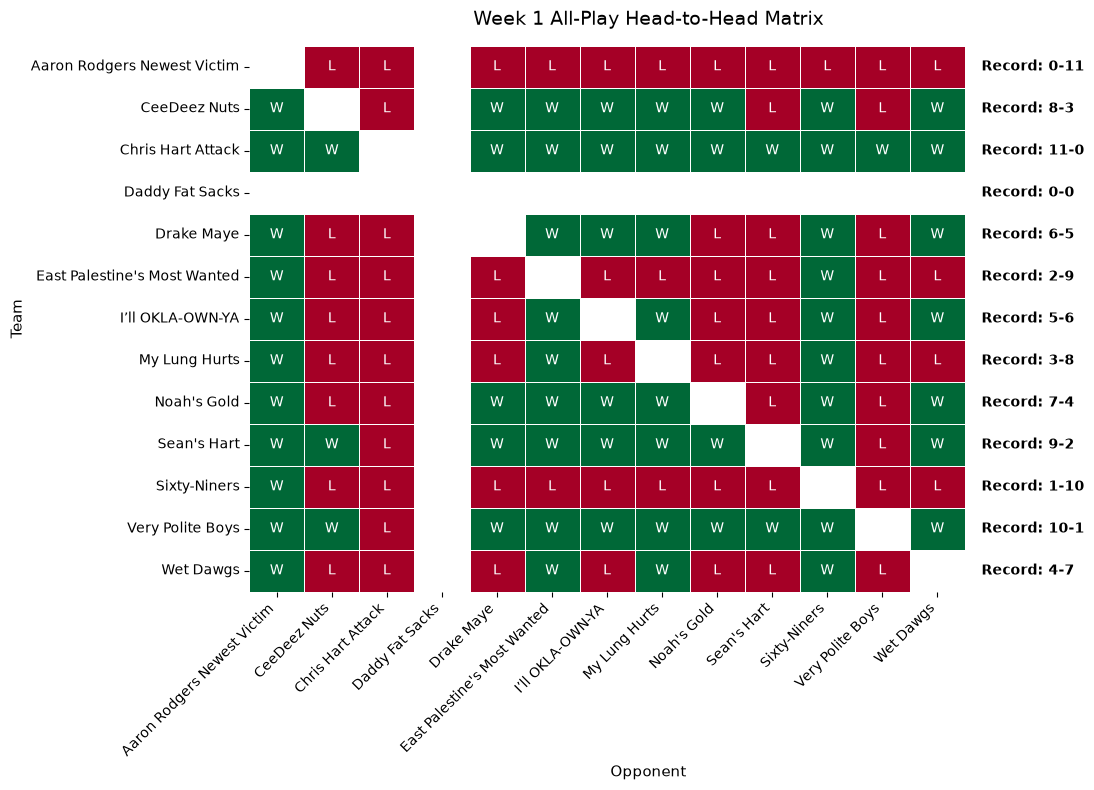

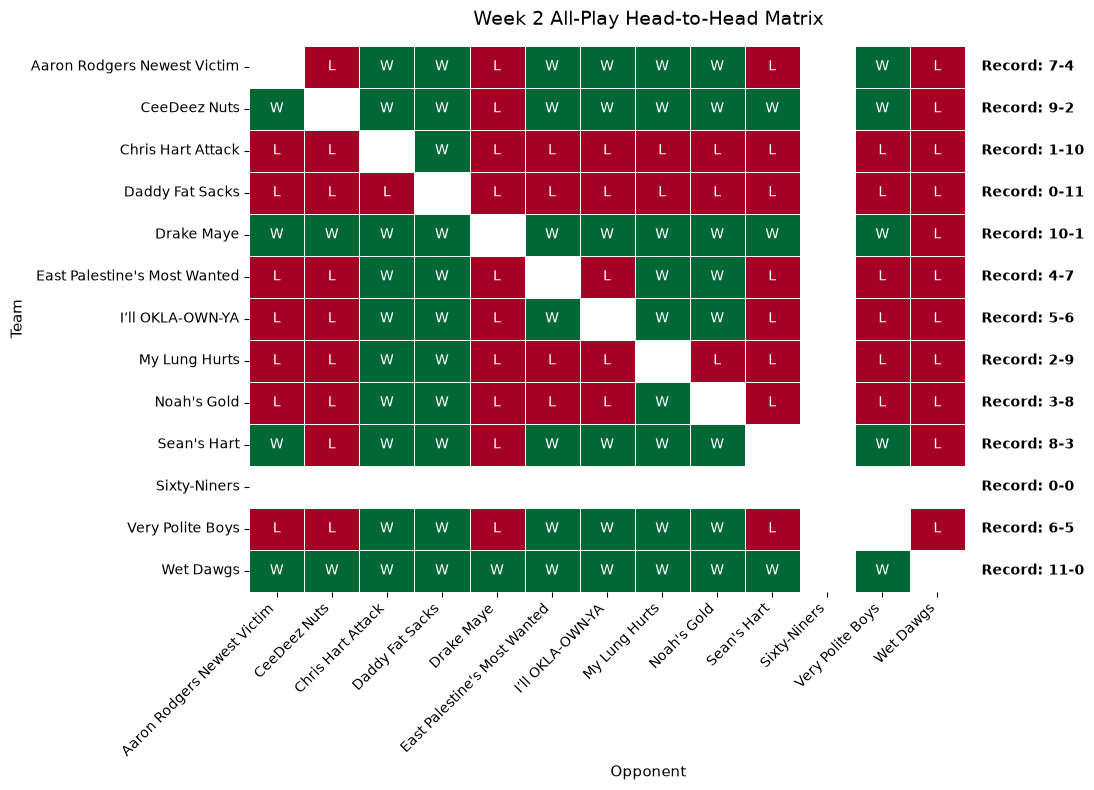

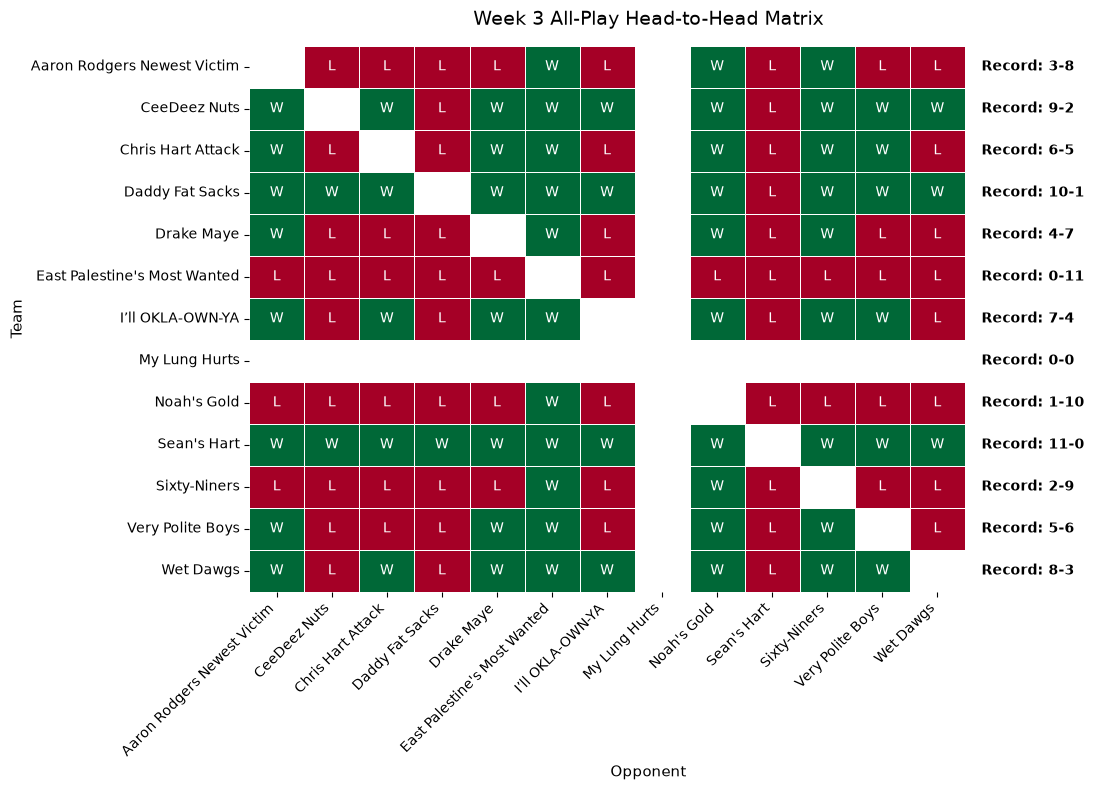

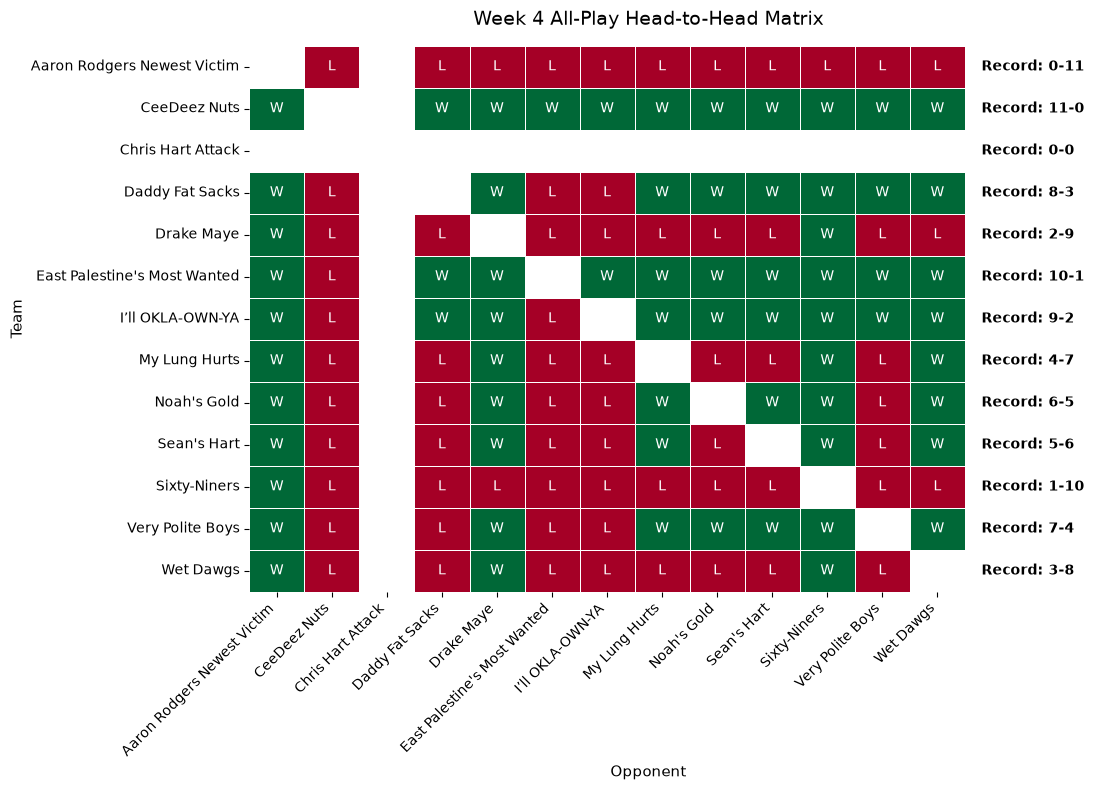

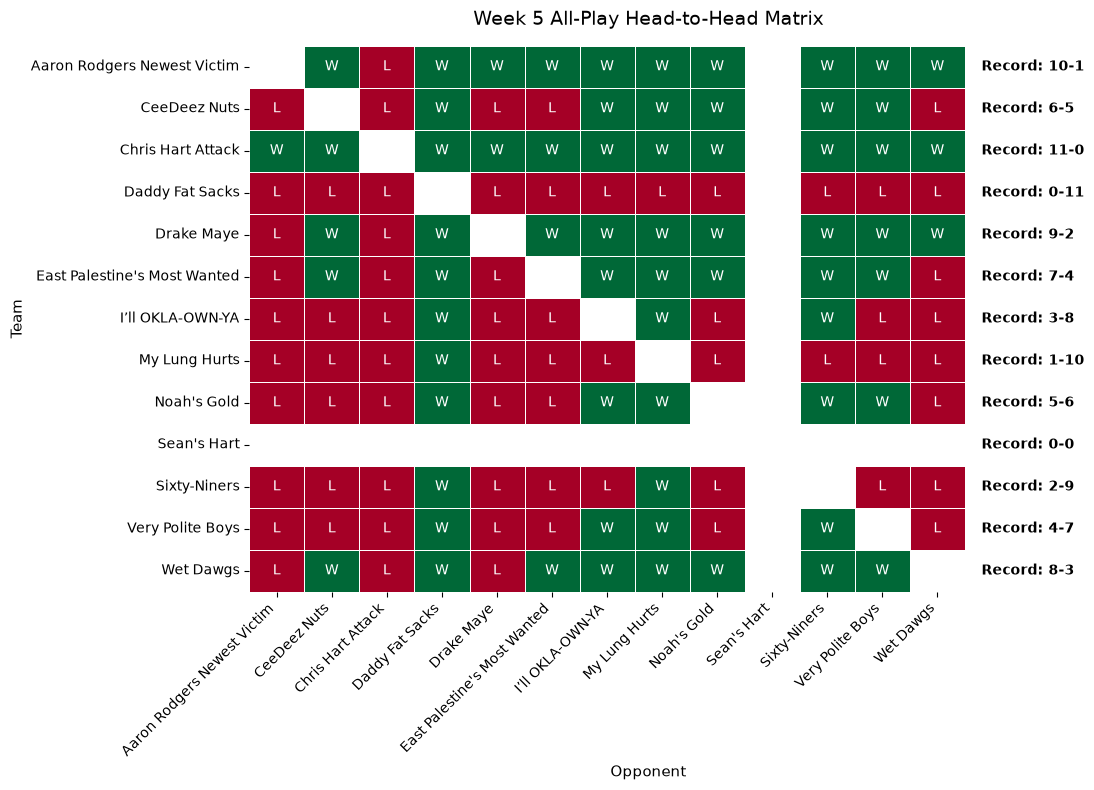

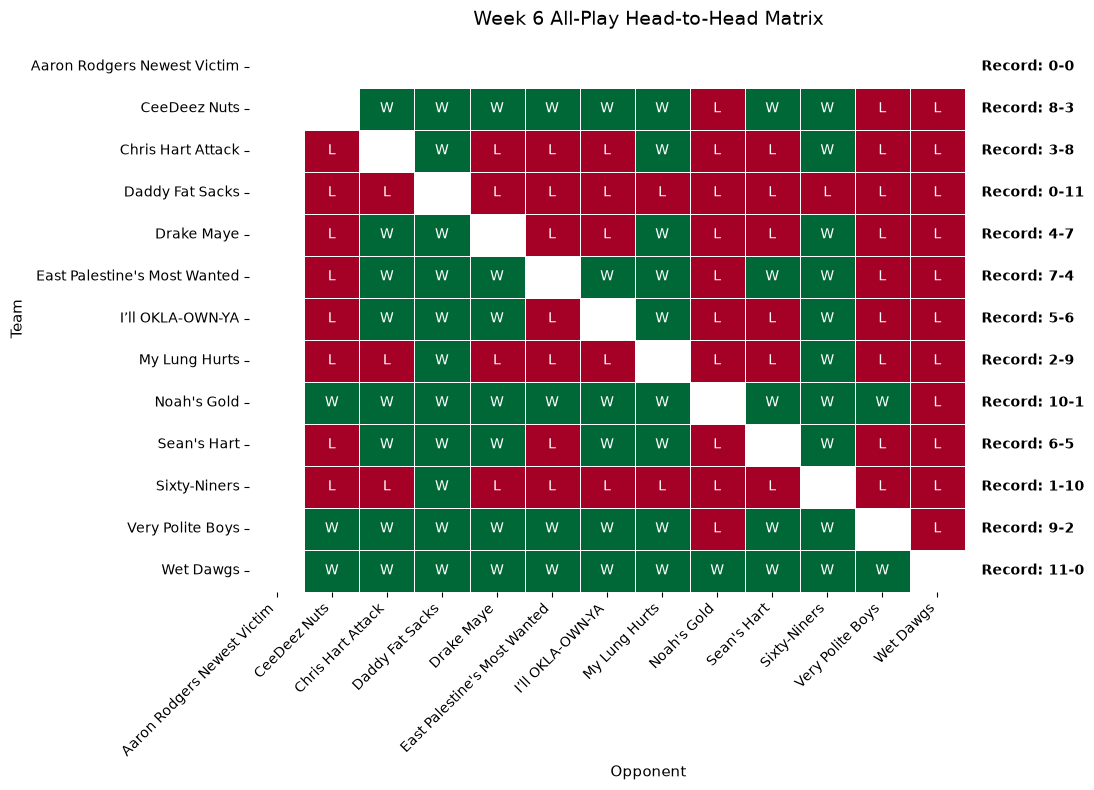

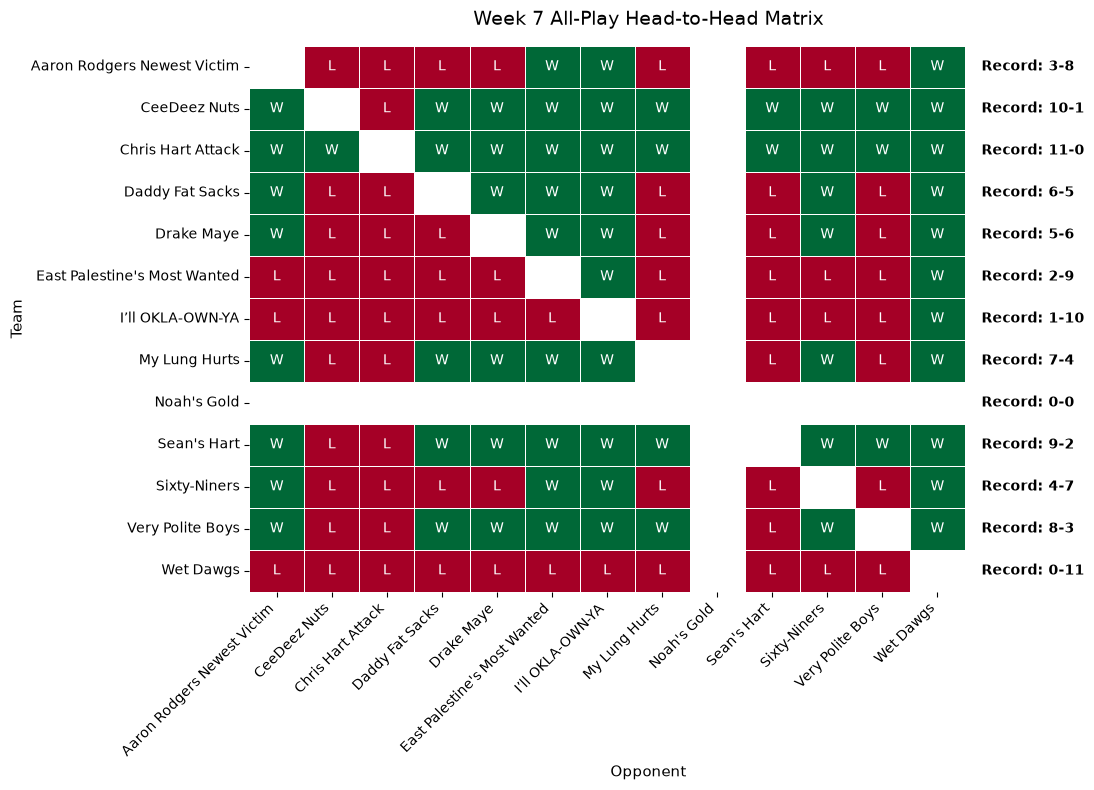

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")
df = df.dropna(subset=["Team Name", "Score"]).copy()
df_played = df[df["Status"] == "Played"].copy()

teams = sorted(df_played["Team Name"].unique())

# 2. Loop through each week and generate a color-coded heatmap matrix
for week_num, group in df_played.groupby("Week"):
  scores = group.set_index("Team Name")["Score"].to_dict()

  matrix_data = {}
  numeric_matrix = {}

  for t1 in teams:
    matrix_data[t1] = {}
    numeric_matrix[t1] = {}
    score_1 = scores.get(t1, np.nan)

    for t2 in teams:
      # Skip self-matches or teams that didn't play this week
      if t1 == t2 or pd.isna(score_1) or t2 not in scores:
        matrix_data[t1][t2] = ""
        numeric_matrix[t1][t2] = np.nan
        continue

      score_2 = scores[t2]

      # Assign W/L text for annotations and 1/0 for color coding
      if score_1 > score_2:
        matrix_data[t1][t2] = "W"
        numeric_matrix[t1][t2] = 1  # Win = Green
      elif score_1 < score_2:
        matrix_data[t1][t2] = "L"
        numeric_matrix[t1][t2] = 0  # Loss = Red
      else:
        matrix_data[t1][t2] = "T"
        numeric_matrix[t1][t2] = 0.5

  # Convert to DataFrames
  df_text = pd.DataFrame(matrix_data).T[teams]
  df_num = pd.DataFrame(numeric_matrix).T[teams]

  # Calculate total wins for the side label
  total_wins = (df_text == "W").sum(axis=1)
  total_losses = (df_text == "L").sum(axis=1)
  records = [f"{w}-{l}" for w, l in zip(total_wins, total_losses)]
  df_text["Record"] = records

  # Plot the heatmap
  plt.figure(figsize=(11, 8))
  ax = sns.heatmap(
      df_num,
      annot=df_text.drop(columns=["Record"]).values,
      fmt="",
      cmap="RdYlGn",
      vmin=0,
      vmax=1,
      linewidths=0.5,
      cbar=False,
  )

  # Customizations
  plt.title(
      f"Week {week_num} All-Play Head-to-Head Matrix", fontsize=14, pad=15
  )
  plt.xlabel("Opponent", fontsize=11)
  plt.ylabel("Team", fontsize=11)
  plt.xticks(rotation=45, ha="right")
  plt.yticks(rotation=0)

  # Attach the weekly total record to the right side of the plot
  ylocs = ax.get_yticks()
  for i, record in enumerate(records):
    ax.text(
        len(teams) + 0.3,
        ylocs[i],
        f"Record: {record}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
    )

  plt.xlim(0, len(teams) + 1.5)
  plt.tight_layout()
  plt.show()

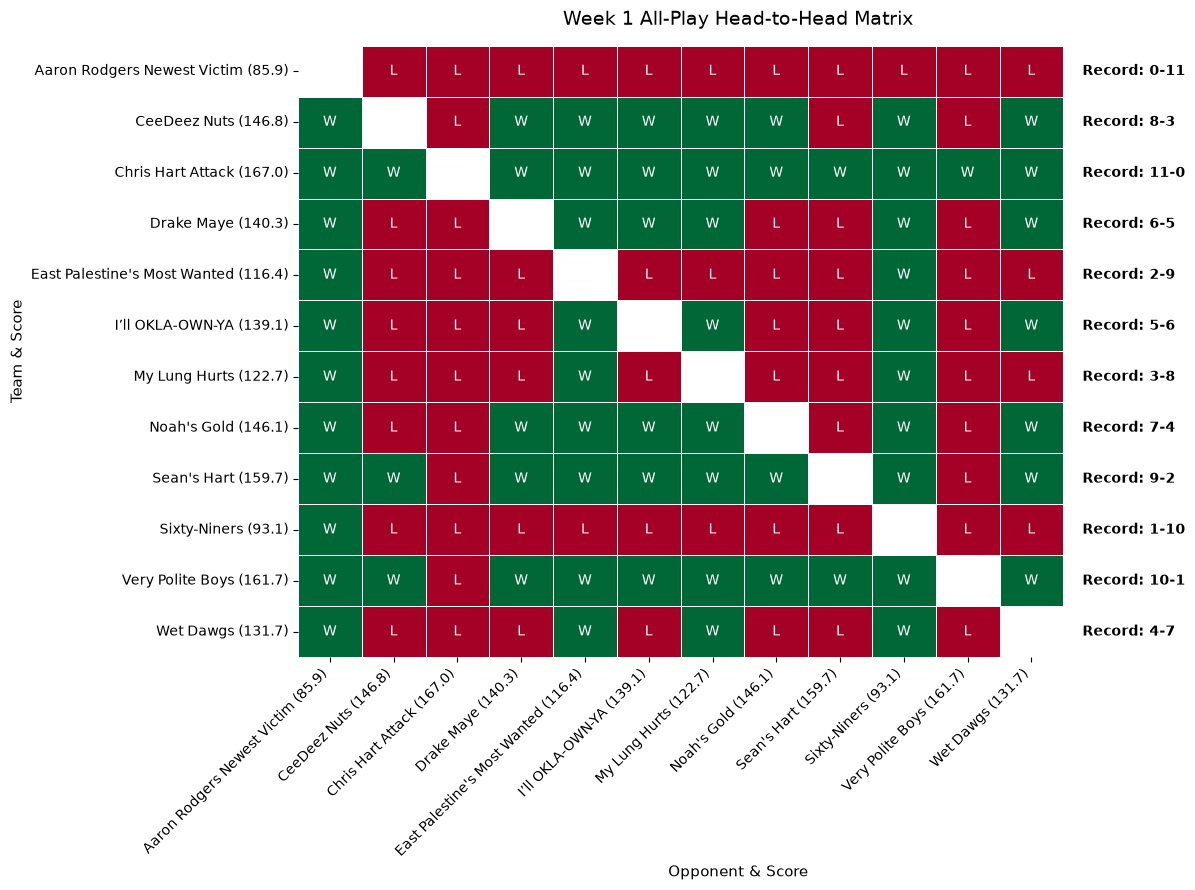

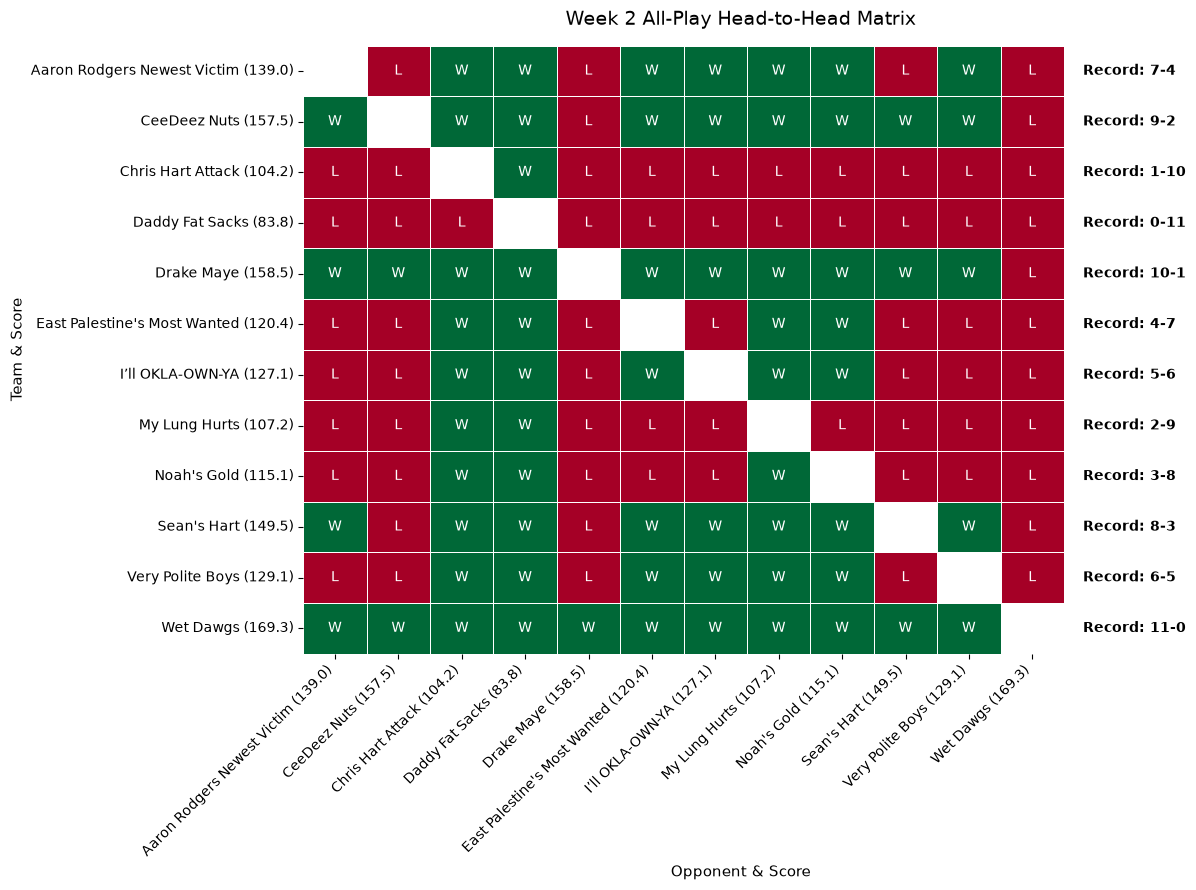

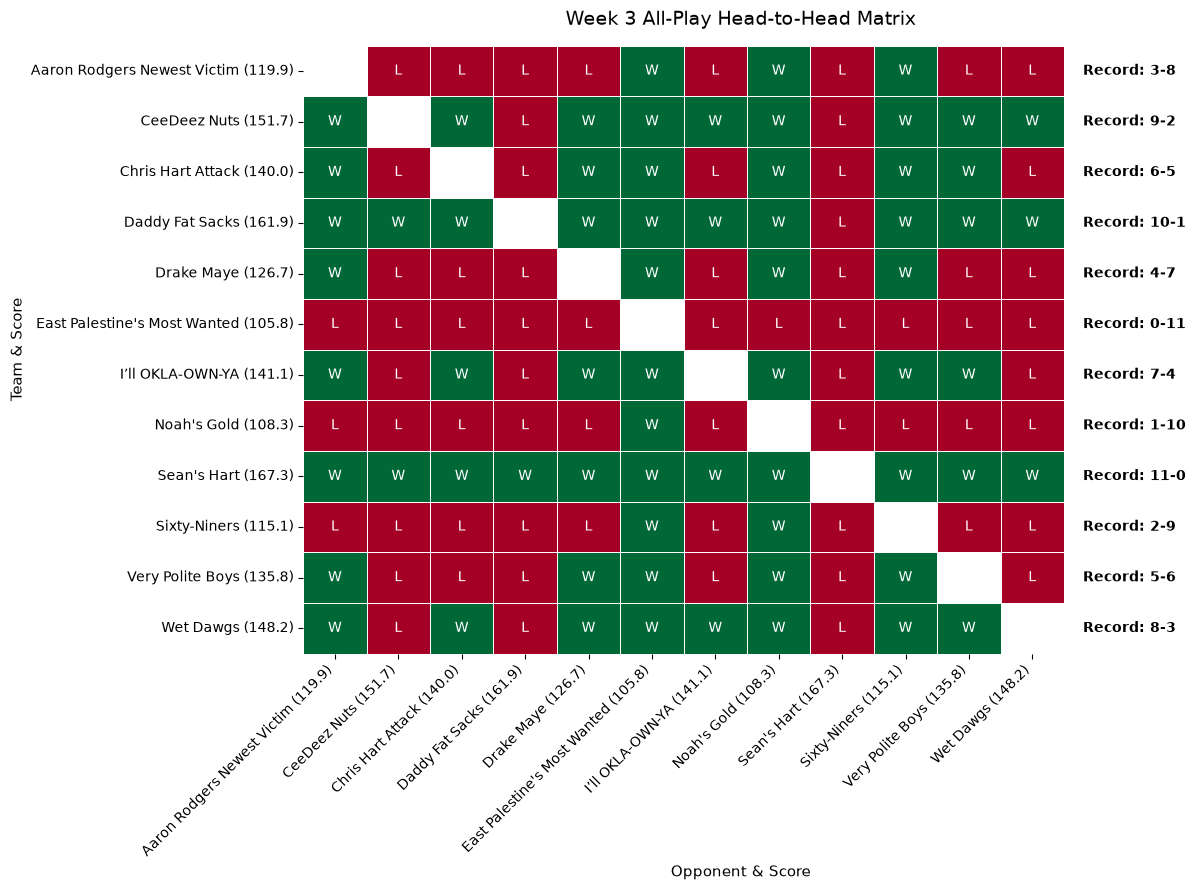

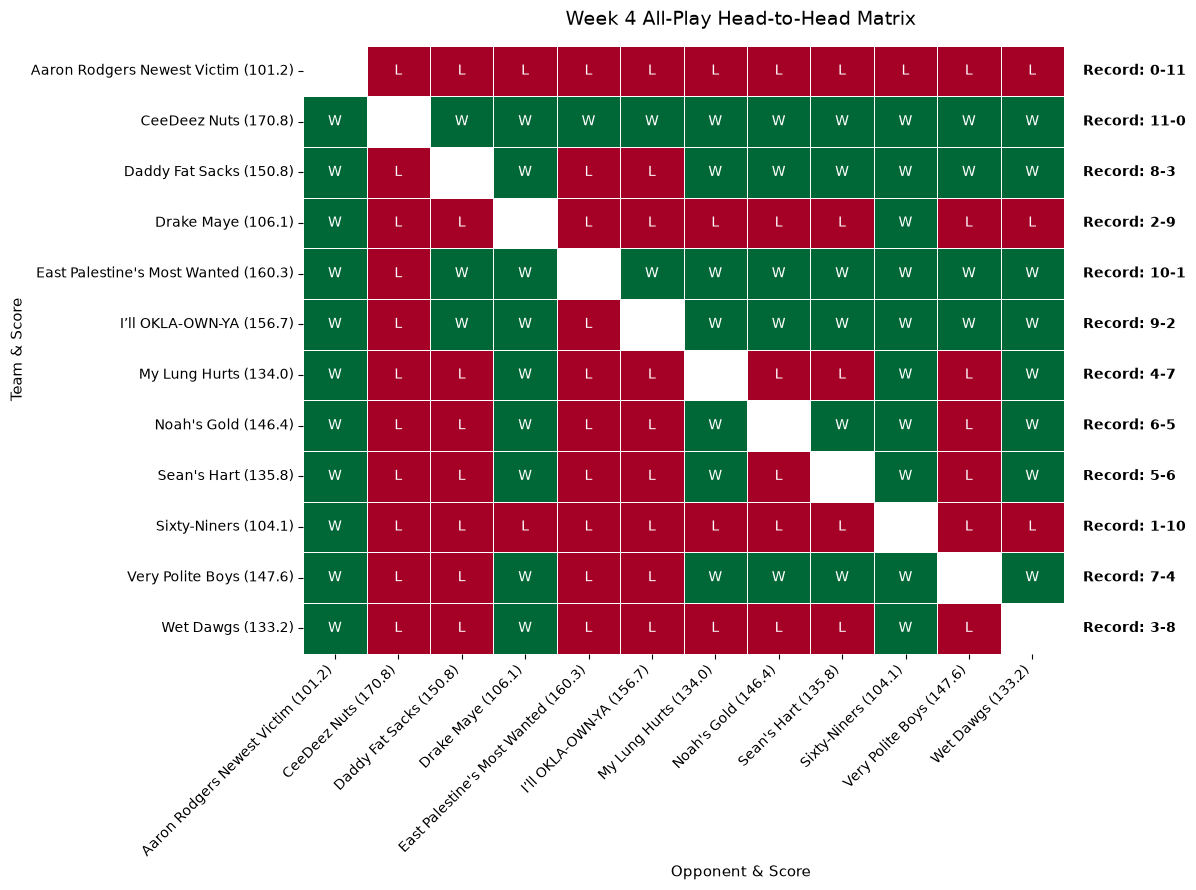

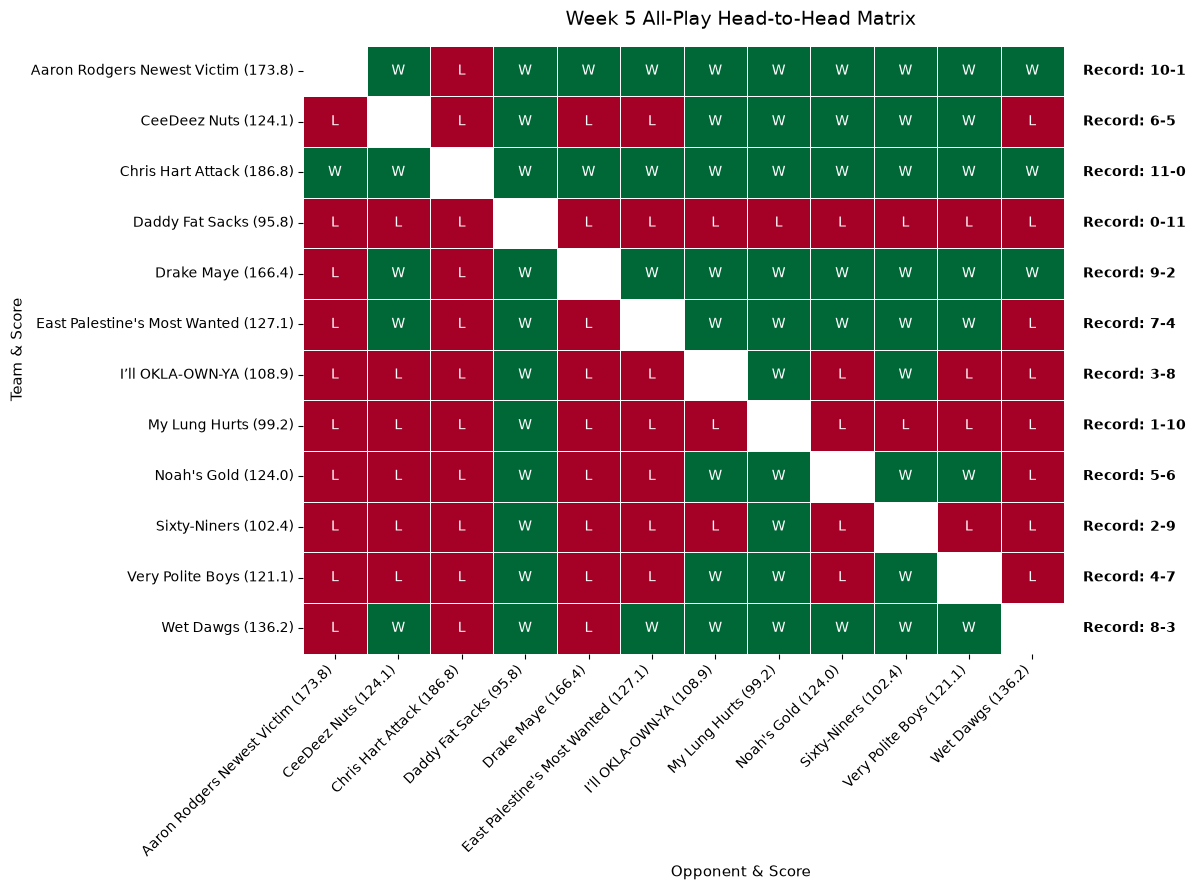

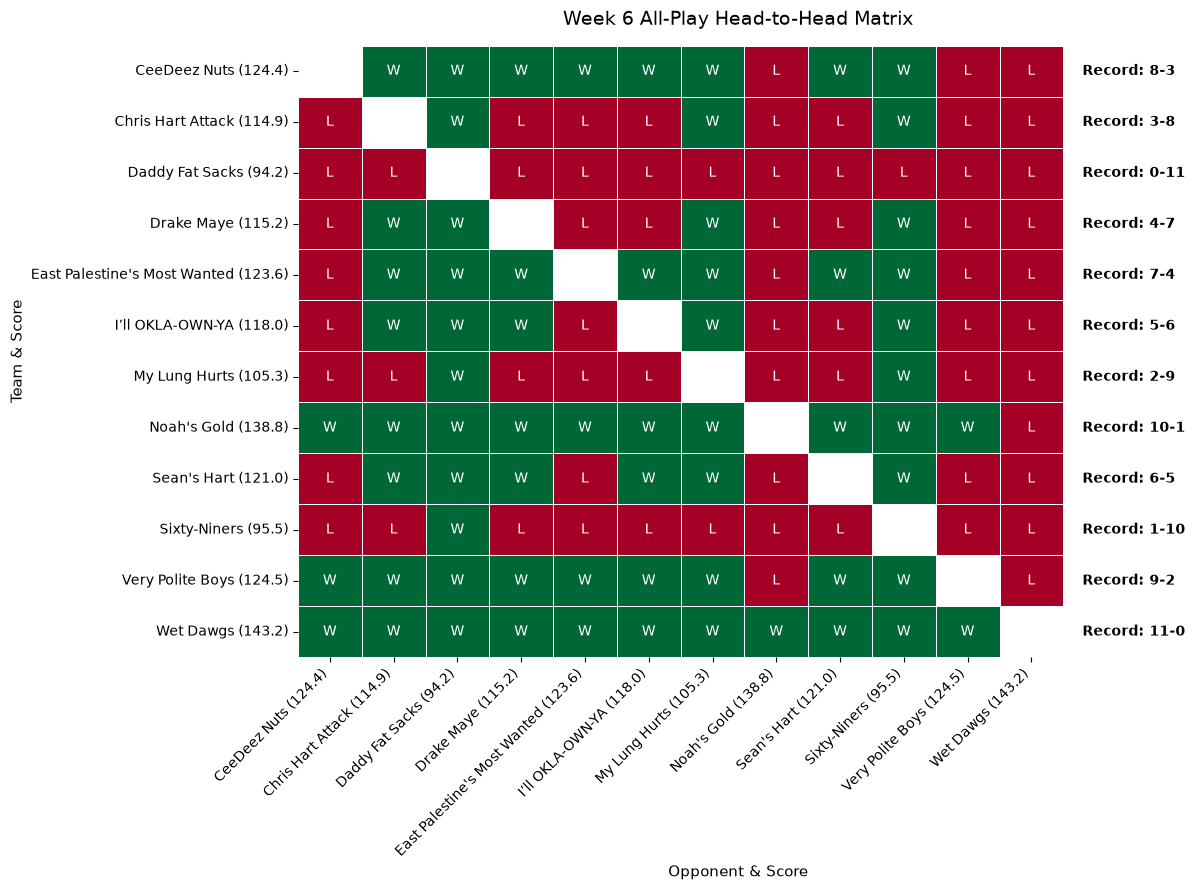

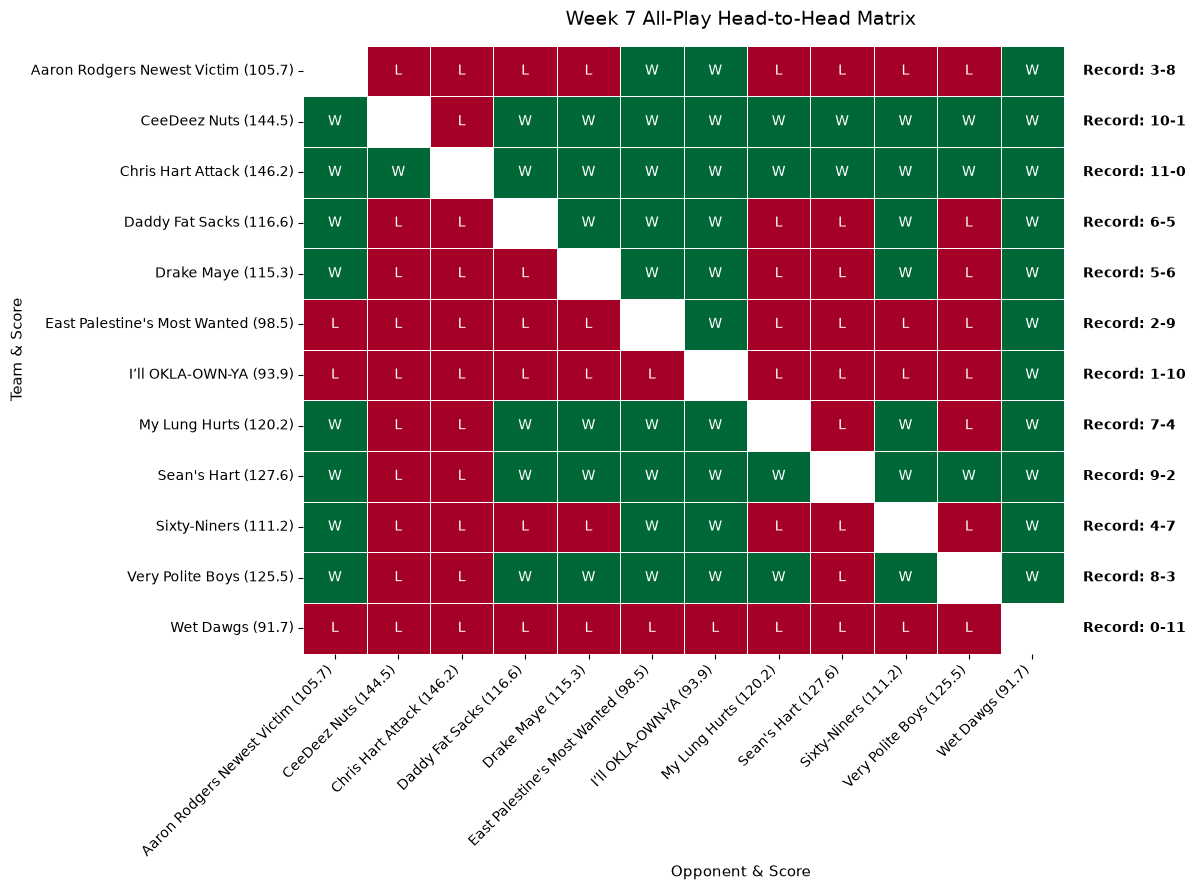

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")
df = df.dropna(subset=["Team Name", "Score"]).copy()
df_played = df[df["Status"] == "Played"].copy()

# 2. Loop through each week and generate a color-coded heatmap matrix
for week_num, group in df_played.groupby("Week"):
  # Filter out anyone on a bye or missing scores for this week
  week_df = group.dropna(subset=["Score"])
  scores = week_df.set_index("Team Name")["Score"].to_dict()

  # Create dynamic labels with scores included (e.g., "Team A (142.5)")
  active_teams = sorted(scores.keys())
  team_labels = [f"{team} ({scores[team]:.1f})" for team in active_teams]

  matrix_data = {}
  numeric_matrix = {}

  for t1 in active_teams:
    matrix_data[t1] = {}
    numeric_matrix[t1] = {}
    score_1 = scores[t1]

    for t2 in active_teams:
      # Skip self-matches
      if t1 == t2:
        matrix_data[t1][t2] = ""
        numeric_matrix[t1][t2] = np.nan
        continue

      score_2 = scores[t2]

      # Assign W/L text for annotations and 1/0 for color coding
      if score_1 > score_2:
        matrix_data[t1][t2] = "W"
        numeric_matrix[t1][t2] = 1  # Win = Green
      elif score_1 < score_2:
        matrix_data[t1][t2] = "L"
        numeric_matrix[t1][t2] = 0  # Loss = Red
      else:
        matrix_data[t1][t2] = "T"
        numeric_matrix[t1][t2] = 0.5

  # Convert to DataFrames using active teams
  df_text = pd.DataFrame(matrix_data).T[active_teams]
  df_num = pd.DataFrame(numeric_matrix).T[active_teams]

  # Calculate total wins and losses for the side label
  total_wins = (df_text == "W").sum(axis=1)
  total_losses = (df_text == "L").sum(axis=1)
  records = [f"{w}-{l}" for w, l in zip(total_wins, total_losses)]
  df_text["Record"] = records

  # Plot the heatmap
  plt.figure(figsize=(12, 9))
  ax = sns.heatmap(
      df_num,
      annot=df_text.drop(columns=["Record"]).values,
      fmt="",
      cmap="RdYlGn",
      vmin=0,
      vmax=1,
      linewidths=0.5,
      cbar=False,
      xticklabels=team_labels,
      yticklabels=team_labels,
  )

  # Customizations
  plt.title(
      f"Week {week_num} All-Play Head-to-Head Matrix", fontsize=14, pad=15
  )
  plt.xlabel("Opponent & Score", fontsize=11)
  plt.ylabel("Team & Score", fontsize=11)
  plt.xticks(rotation=45, ha="right")
  plt.yticks(rotation=0)

  # Attach the weekly total record to the right side of the plot
  ylocs = ax.get_yticks()
  for i, record in enumerate(records):
    ax.text(
        len(active_teams) + 0.3,
        ylocs[i],
        f"Record: {record}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
    )

  plt.xlim(0, len(active_teams) + 1.8)
  plt.tight_layout()
  plt.show()

In [53]:
df

,Week,Team ID,Team Name,Score,Status
0,1,15,Chris Hart Attack,166.96,Played
1,1,3,Very Polite Boys,161.66,Played
2,1,10,Daddy Fat Sacks,126.62,Bye
3,1,13,Noah's Gold,146.10,Played
4,1,7,East Palestine's Most Wanted,116.36,Played
...,...,...,...,...,...
86,7,7,East Palestine's Most Wanted,98.54,Played
87,7,6,Sixty-Niners,111.24,Played
88,7,9,Sean's Hart,127.60,Played
89,7,2,Wet Dawgs,91.68,Played


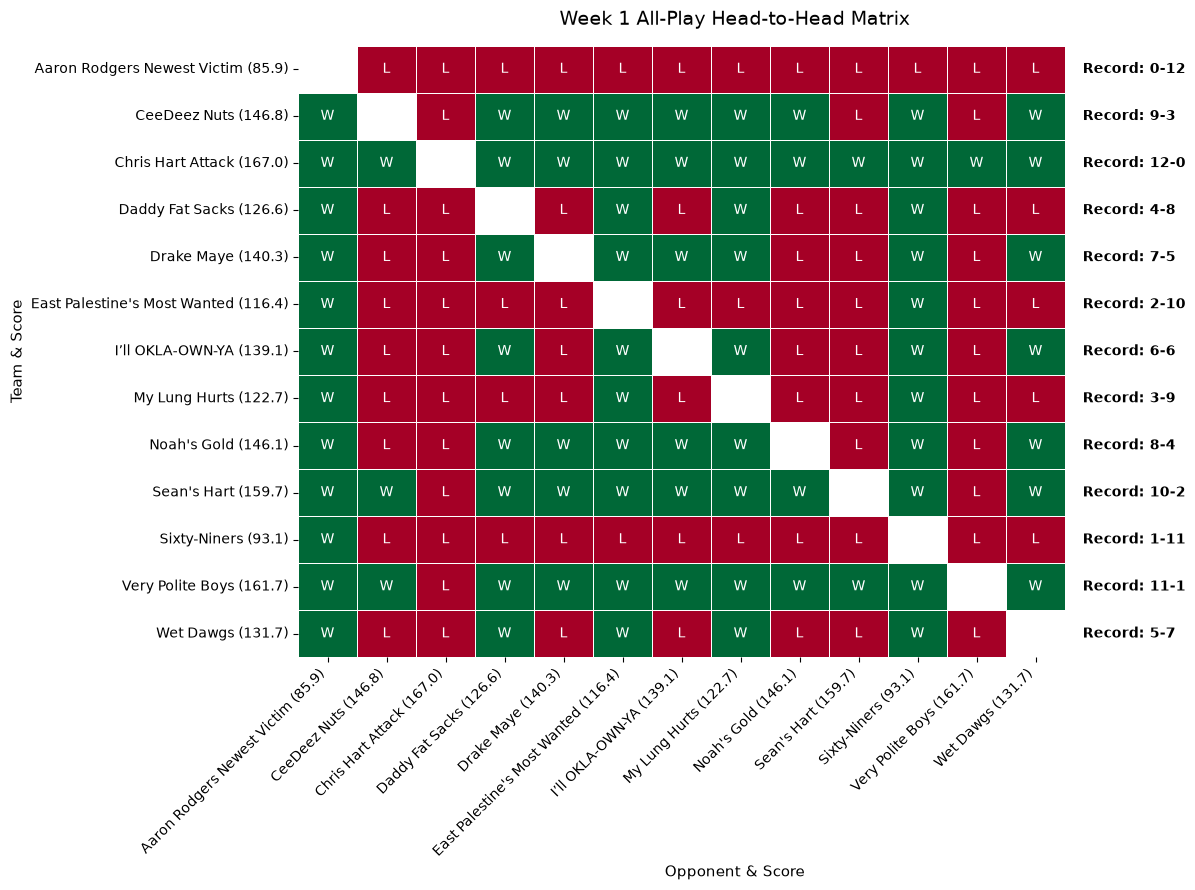

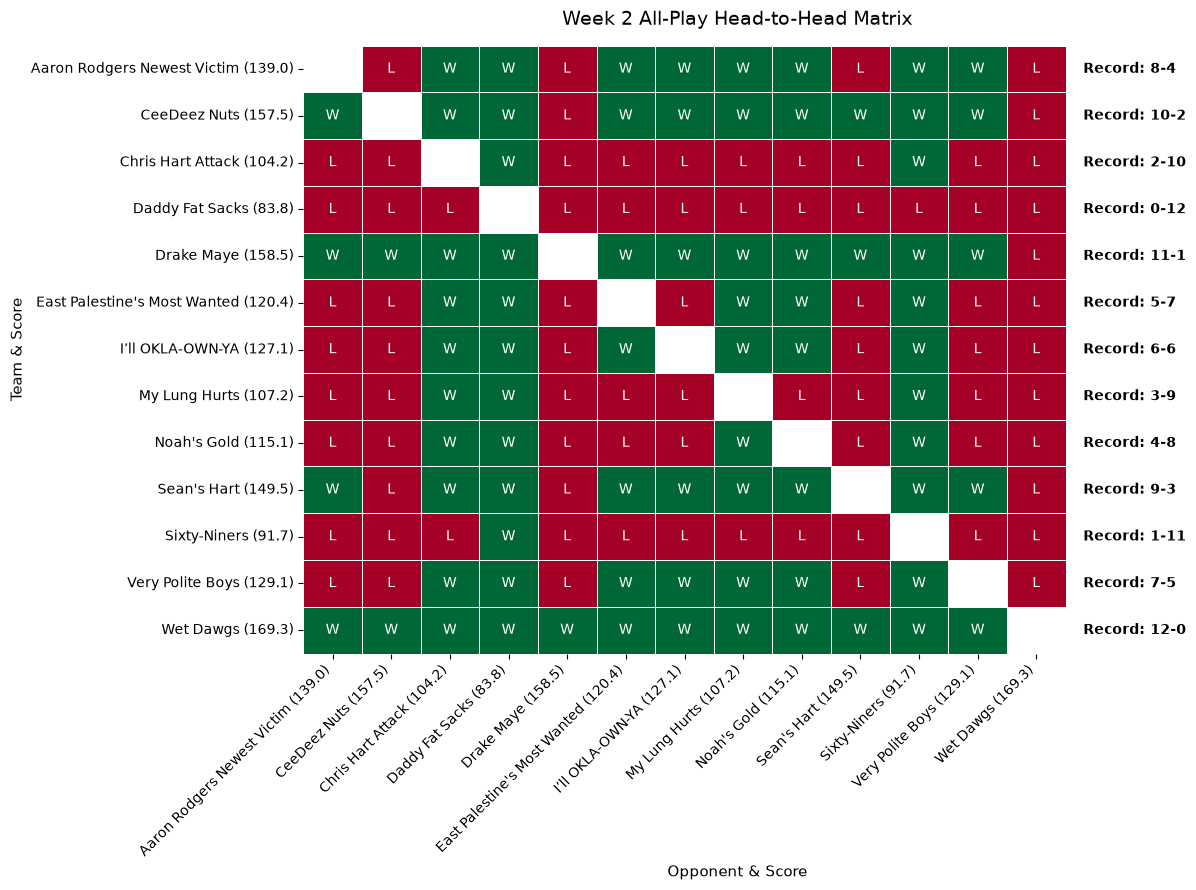

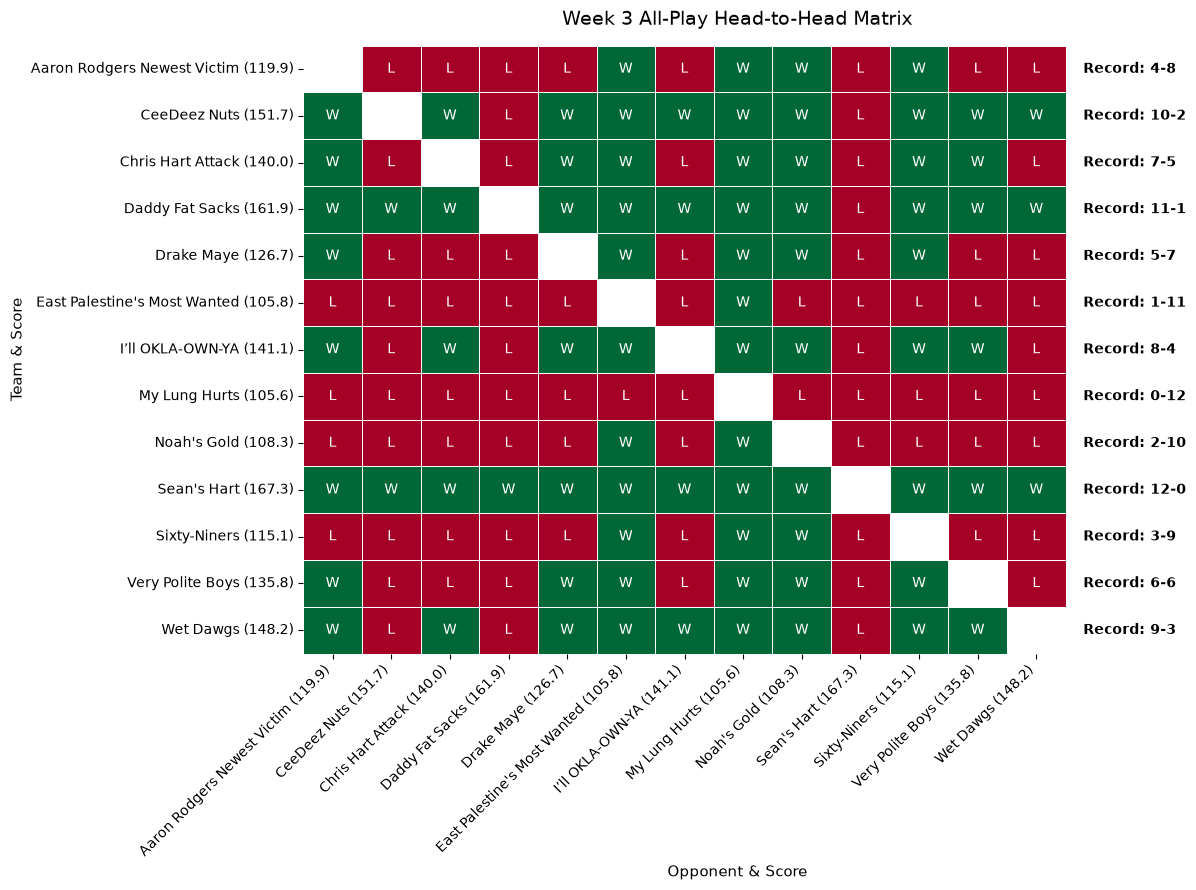

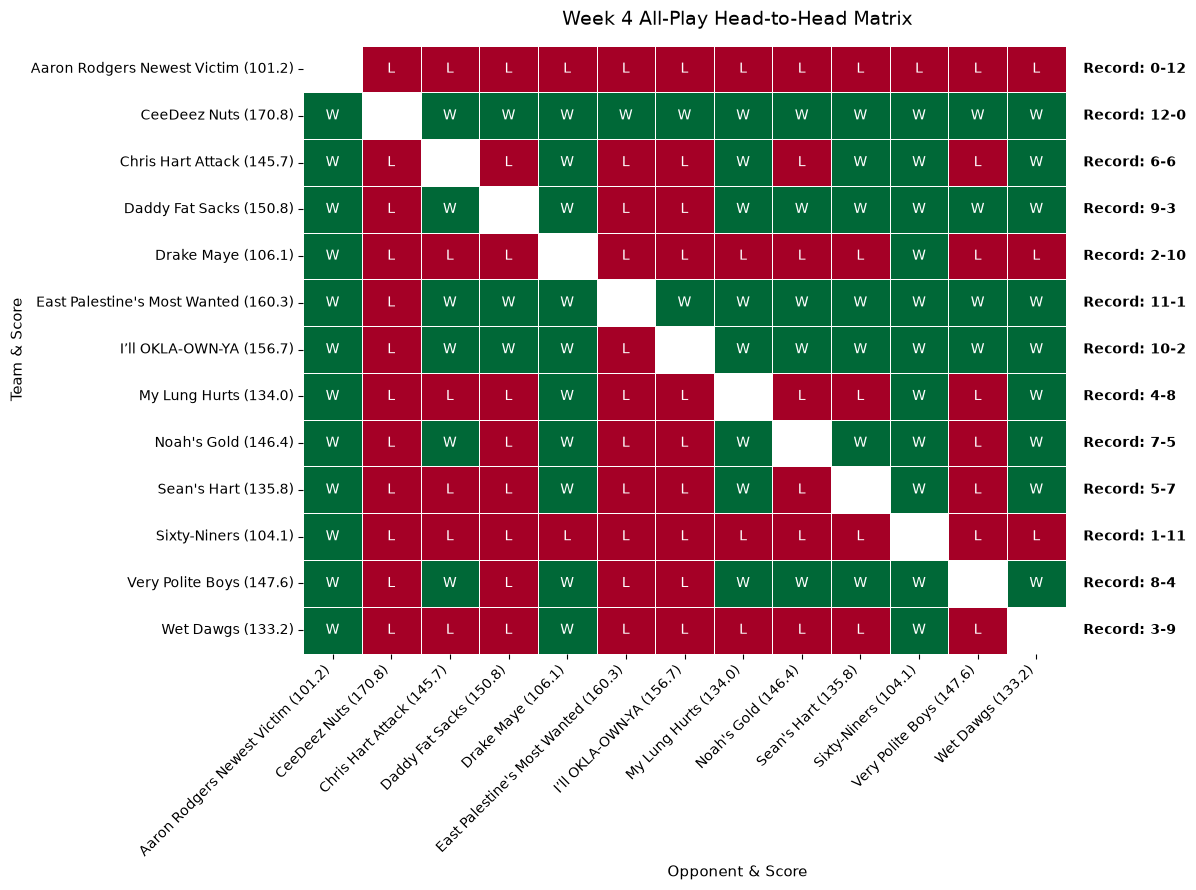

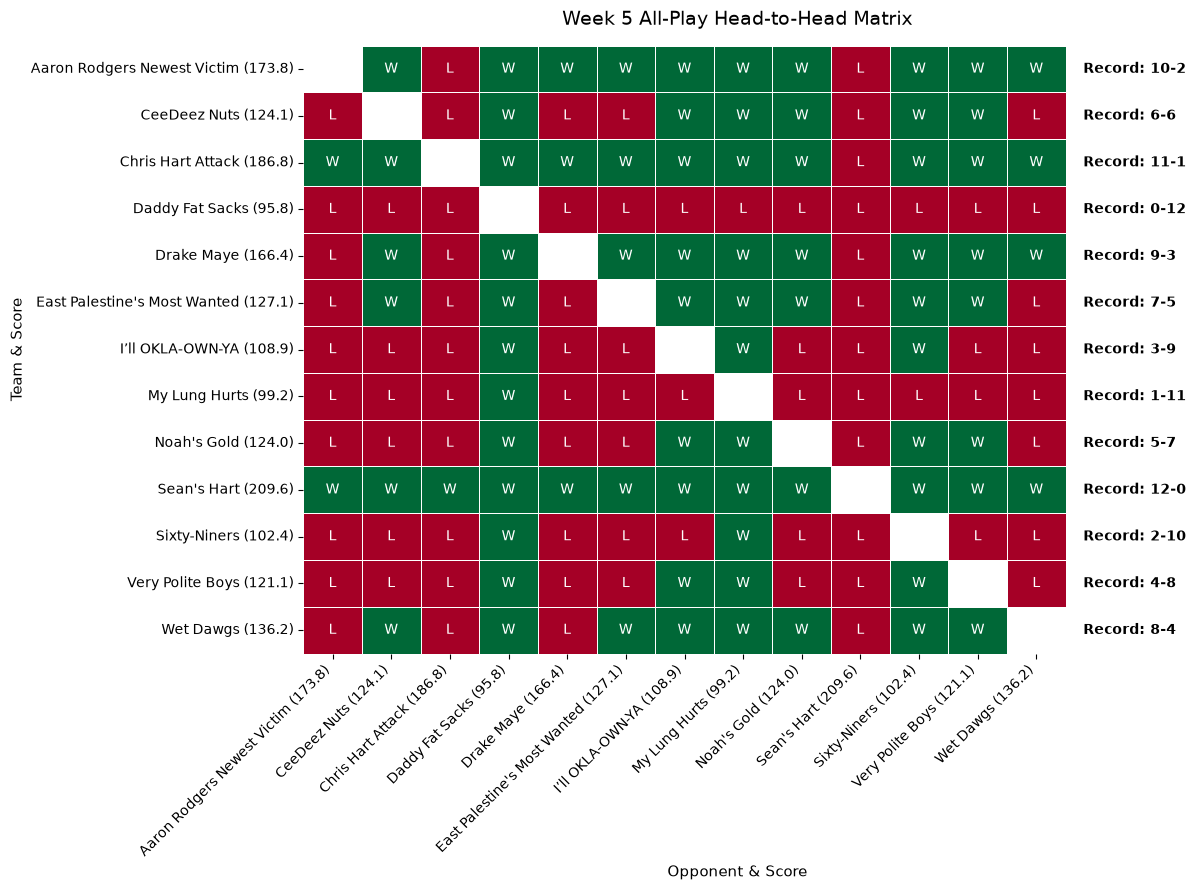

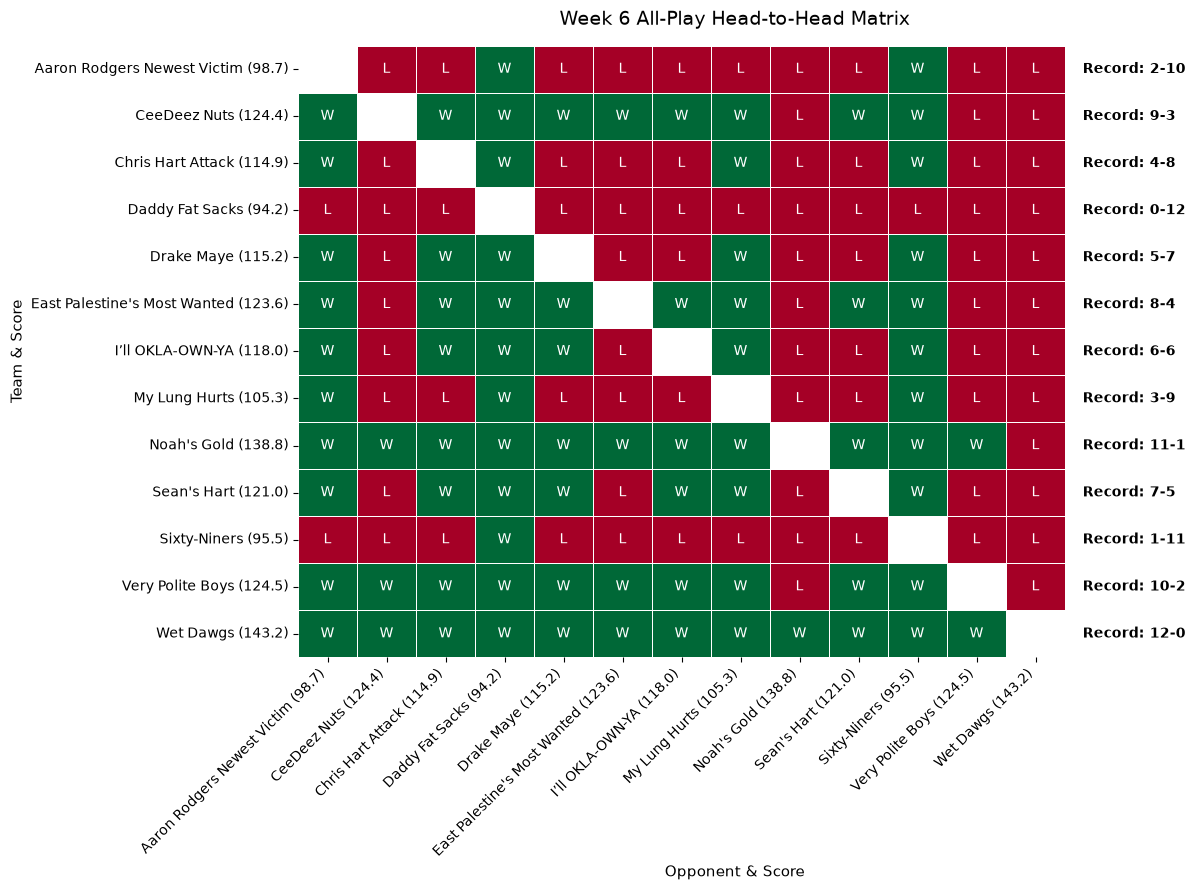

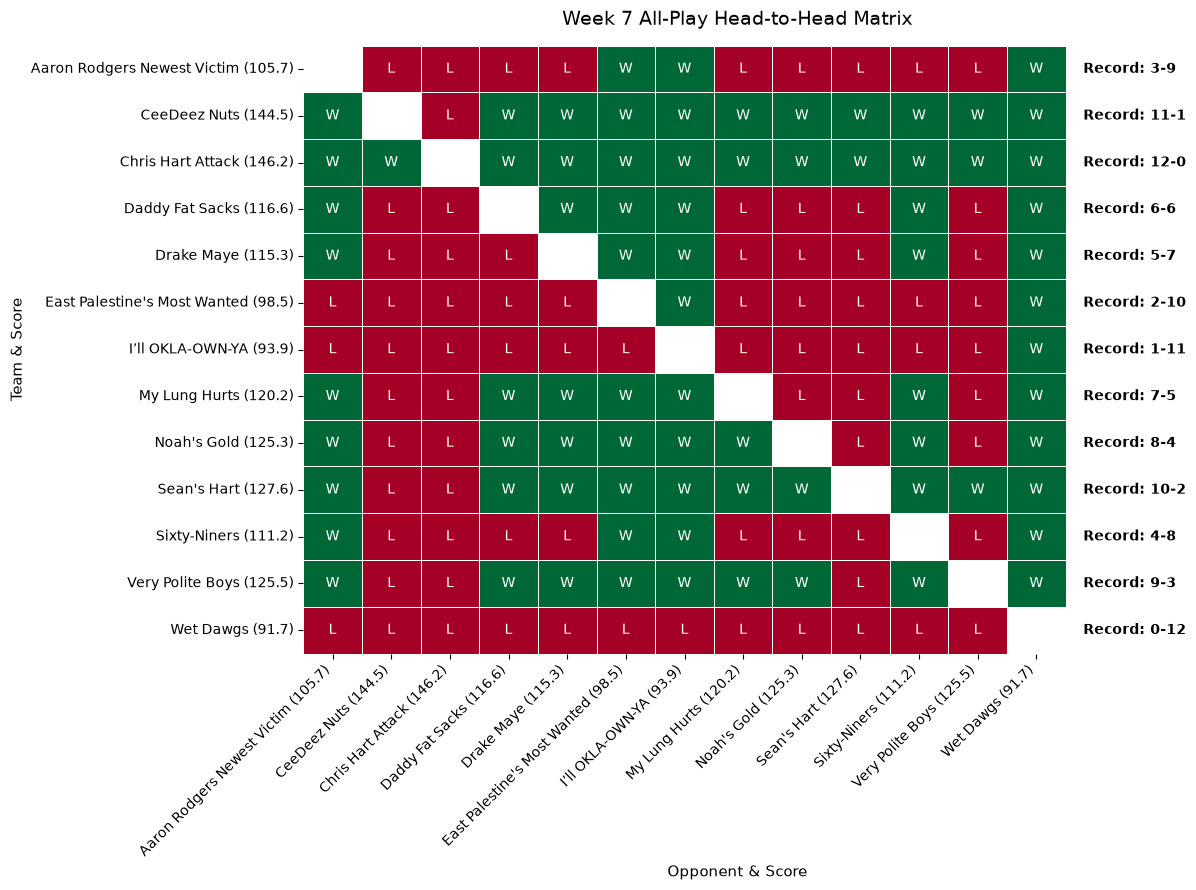

In [58]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load your weekly scores file
df = pd.read_csv("every_team_weekly_scores.csv")
df = df.dropna(subset=["Team Name", "Score"]).copy()


# 2. Loop through each week and generate a color-coded heatmap matrix
for week_num, group in df.groupby("Week"):
  # Filter out anyone on a bye or missing scores for this week
  week_df = group.dropna(subset=["Score"])
  scores = week_df.set_index("Team Name")["Score"].to_dict()

  # Create dynamic labels with scores included (e.g., "Team A (142.5)")
  active_teams = sorted(scores.keys())
  team_labels = [f"{team} ({scores[team]:.1f})" for team in active_teams]

  matrix_data = {}
  numeric_matrix = {}

  for t1 in active_teams:
    matrix_data[t1] = {}
    numeric_matrix[t1] = {}
    score_1 = scores[t1]

    for t2 in active_teams:
      # Skip self-matches
      if t1 == t2:
        matrix_data[t1][t2] = ""
        numeric_matrix[t1][t2] = np.nan
        continue

      score_2 = scores[t2]

      # Assign W/L text for annotations and 1/0 for color coding
      if score_1 > score_2:
        matrix_data[t1][t2] = "W"
        numeric_matrix[t1][t2] = 1  # Win = Green
      elif score_1 < score_2:
        matrix_data[t1][t2] = "L"
        numeric_matrix[t1][t2] = 0  # Loss = Red
      else:
        matrix_data[t1][t2] = "T"
        numeric_matrix[t1][t2] = 0.5

  # Convert to DataFrames using active teams
  df_text = pd.DataFrame(matrix_data).T[active_teams]
  df_num = pd.DataFrame(numeric_matrix).T[active_teams]

  # Calculate total wins and losses for the side label
  total_wins = (df_text == "W").sum(axis=1)
  total_losses = (df_text == "L").sum(axis=1)
  records = [f"{w}-{l}" for w, l in zip(total_wins, total_losses)]
  df_text["Record"] = records

  # Plot the heatmap
  plt.figure(figsize=(12, 9))
  ax = sns.heatmap(
      df_num,
      annot=df_text.drop(columns=["Record"]).values,
      fmt="",
      cmap="RdYlGn",
      vmin=0,
      vmax=1,
      linewidths=0.5,
      cbar=False,
      xticklabels=team_labels,
      yticklabels=team_labels,
  )

  # Customizations
  plt.title(
      f"Week {week_num} All-Play Head-to-Head Matrix", fontsize=14, pad=15
  )
  plt.xlabel("Opponent & Score", fontsize=11)
  plt.ylabel("Team & Score", fontsize=11)
  plt.xticks(rotation=45, ha="right")
  plt.yticks(rotation=0)

  # Attach the weekly total record to the right side of the plot
  ylocs = ax.get_yticks()
  for i, record in enumerate(records):
    ax.text(
        len(active_teams) + 0.3,
        ylocs[i],
        f"Record: {record}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
    )

  plt.xlim(0, len(active_teams) + 1.8)
  plt.tight_layout()
  plt.show()

In [59]:
active_teams

['Aaron Rodgers Newest Victim',
 'CeeDeez Nuts',
 'Chris Hart Attack',
 'Daddy Fat Sacks',
 'Drake Maye',
 "East Palestine's Most Wanted",
 'I’ll OKLA-OWN-YA',
 'My Lung Hurts',
 "Noah's Gold",
 "Sean's Hart",
 'Sixty-Niners',
 'Very Polite Boys',
 'Wet Dawgs']

In [55]:
df

,Week,Team ID,Team Name,Score,Status
0,1,15,Chris Hart Attack,166.96,Played
1,1,3,Very Polite Boys,161.66,Played
2,1,10,Daddy Fat Sacks,126.62,Bye
3,1,13,Noah's Gold,146.10,Played
4,1,7,East Palestine's Most Wanted,116.36,Played
...,...,...,...,...,...
86,7,7,East Palestine's Most Wanted,98.54,Played
87,7,6,Sixty-Niners,111.24,Played
88,7,9,Sean's Hart,127.60,Played
89,7,2,Wet Dawgs,91.68,Played


In [56]:
df.head(13)

,Week,Team ID,Team Name,Score,Status
0,1,15,Chris Hart Attack,166.96,Played
1,1,3,Very Polite Boys,161.66,Played
2,1,10,Daddy Fat Sacks,126.62,Bye
3,1,13,Noah's Gold,146.10,Played
4,1,7,East Palestine's Most Wanted,116.36,Played
5,1,1,My Lung Hurts,122.68,Played
6,1,9,Sean's Hart,159.70,Played
7,1,11,CeeDeez Nuts,146.80,Played
8,1,12,I’ll OKLA-OWN-YA,139.08,Played
9,1,5,Aaron Rodgers Newest Victim,85.94,Played


In [57]:
df.head(20)

,Week,Team ID,Team Name,Score,Status
0,1,15,Chris Hart Attack,166.96,Played
1,1,3,Very Polite Boys,161.66,Played
2,1,10,Daddy Fat Sacks,126.62,Bye
3,1,13,Noah's Gold,146.10,Played
4,1,7,East Palestine's Most Wanted,116.36,Played
5,1,1,My Lung Hurts,122.68,Played
6,1,9,Sean's Hart,159.70,Played
7,1,11,CeeDeez Nuts,146.80,Played
8,1,12,I’ll OKLA-OWN-YA,139.08,Played
9,1,5,Aaron Rodgers Newest Victim,85.94,Played


In [60]:
%pwd


'C:\\Users\\seanm'